# 03 · Delivery ETA model

> **Simulated data.** Orders come from `pulso_exp.simulate` (seed 42). Pulso is a fictional company.

When a merchant creates an order, Pulso quotes a delivery time. Today the quote is a legacy rule,
`eta = 10 + 4 · straight-line km`. A bad quote hurts twice: too optimistic and the order is "late" (refunds, support
tickets); too pessimistic and the merchant picks another channel.

**Goal:** a model that predicts delivery minutes at the moment the order is assigned, compared honestly against
simple baselines, with an uncertainty band we can quote and a realistic view of serving cost.

In [1]:
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression

from pulso_exp.clean import clean_orders, find_bot_merchants
from pulso_exp.plotting import INK_SECONDARY, SERIES, apply_style
from pulso_exp.simulate import SimConfig, simulate

apply_style()
data = simulate(SimConfig())
orders = clean_orders(data.orders, bot_merchants=find_bot_merchants(data.sessions))
print(
    f"{len(orders):,} orders, {orders['status'].eq('DELIVERED').sum():,} delivered, {orders['stuck'].sum()} stuck"
)

56,071 orders, 53,695 delivered, 153 stuck


## 1 · Features: only what is known at assignment time

Every feature must exist **when the quote is shown**. That rules out `delivery_minutes` itself, `status`,
`refund_issued` and anything measured after pickup. `pulser_id` is left out on purpose: it is high-cardinality and
useless for new pulsers; the pulser's rating carries the stable part of that signal.

Training rows: delivered orders that are not *stuck* (> 4 h, see notebook 01). Stuck orders are an ops problem, not
information about travel time; they are still counted in the evaluation of how often quotes are badly wrong.

In [2]:
FEATURES = [
    "distance_km",
    "vehicle",
    "city",
    "category",
    "hour",
    "day_of_week",
    "raining",
    "pulser_active_tasks",
    "pulser_rating",
    "items_count",
]
CATEGORICAL = ["vehicle", "city", "category"]


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["distance_km"] = np.hypot(
        (out["dropoff_lat"] - out["pickup_lat"]) * 111.0,
        (out["dropoff_lng"] - out["pickup_lng"]) * 111.0 * np.cos(np.radians(out["pickup_lat"])),
    )
    out["hour"] = out["created_at"].dt.hour
    out["day_of_week"] = out["created_at"].dt.day_of_week
    out["raining"] = out["raining"].astype(int)
    for c in CATEGORICAL:
        out[c] = out[c].astype("category")
    return out


delivered = build_features(orders[orders["status"] == "DELIVERED"]).sort_values("created_at")
model_rows = delivered[~delivered["stuck"]]
model_rows[FEATURES + ["delivery_minutes"]].describe(include="all").T[
    ["count", "mean", "min", "max", "unique"]
]

,count,mean,min,max,unique
distance_km,53542.0,3.833208,0.299542,25.000974,NaN
vehicle,53542,NaN,NaN,NaN,3
city,53542,NaN,NaN,NaN,4
category,53542,NaN,NaN,NaN,5
hour,53542.0,14.599884,0.0,23.0,NaN
day_of_week,53542.0,2.996022,0.0,6.0,NaN
raining,53542.0,0.227485,0.0,1.0,NaN
pulser_active_tasks,53542.0,0.980352,0.0,3.0,NaN
pulser_rating,51432.0,4.638375,3.05,5.0,NaN
items_count,53542.0,2.995798,1.0,14.0,NaN


## 2 · Time-based split

A random split would put orders from the same rainy afternoon in train and test, and the model would look better than
it will in production. Instead: train on the first ~6 weeks, validate (early stopping) on the next week, and test on the
**last ~11 days**, which the model never saw — the way it would be used.

In [3]:
t_valid = model_rows["created_at"].quantile(0.70)
t_test = model_rows["created_at"].quantile(0.80)
train = model_rows[model_rows["created_at"] < t_valid]
valid = model_rows[(model_rows["created_at"] >= t_valid) & (model_rows["created_at"] < t_test)]
test = model_rows[model_rows["created_at"] >= t_test]
test_all = delivered[
    delivered["created_at"] >= t_test
]  # includes stuck orders, for the "badly wrong" rate
pd.DataFrame(
    {
        "rows": [len(train), len(valid), len(test)],
        "from": [train["created_at"].min(), valid["created_at"].min(), test["created_at"].min()],
        "to": [train["created_at"].max(), valid["created_at"].max(), test["created_at"].max()],
    },
    index=["train", "valid", "test"],
)

,rows,from,to
train,37479,2026-03-02 00:08:39,2026-04-10 13:09:18
valid,5354,2026-04-10 13:09:51,2026-04-15 21:14:20
test,10709,2026-04-15 21:14:26,2026-04-27 00:05:11


## 3 · Baselines

A model is only interesting relative to what it replaces:

1. **Global median** of training delivery times — the "know nothing" floor.
2. **Legacy rule** `10 + 4 · km` — what Pulso quotes today.
3. **Linear regression per vehicle** on distance — the obvious next step a team would try first.

In [4]:
y_test = test["delivery_minutes"].to_numpy()
preds = {
    "global median": np.full(len(test), train["delivery_minutes"].median()),
    "legacy rule (10 + 4·km)": test["eta_minutes"].to_numpy(),
}
linear = np.empty(len(test))
for v in ("BIKE", "MOTO", "CAR"):
    tr, te = train["vehicle"] == v, (test["vehicle"] == v).to_numpy()
    lr = LinearRegression().fit(train.loc[tr, ["distance_km"]], train.loc[tr, "delivery_minutes"])
    linear[te] = lr.predict(test.loc[te, ["distance_km"]])
preds["linear on distance, per vehicle"] = linear

## 4 · Gradient boosting

`HistGradientBoostingRegressor`: handles categoricals and missing values (`pulser_rating`) natively, trains in seconds,
and with **absolute-error loss** it targets the median — the right point estimate for a skewed target, and the one MAE
rewards. Early stopping uses the validation week only.

In [5]:
def gbm(**kwargs) -> HistGradientBoostingRegressor:
    return HistGradientBoostingRegressor(
        categorical_features="from_dtype",
        learning_rate=0.05,
        max_iter=1_000,
        max_leaf_nodes=31,
        early_stopping=True,
        validation_fraction=None,
        n_iter_no_change=30,
        random_state=0,
        **kwargs,
    )


X_train, y_train = train[FEATURES], train["delivery_minutes"]
X_valid, y_valid = valid[FEATURES], valid["delivery_minutes"]
X_test = test[FEATURES]

t0 = time.perf_counter()
model = gbm(loss="absolute_error").fit(X_train, y_train, X_val=X_valid, y_val=y_valid)
print(
    f"trained in {time.perf_counter() - t0:.1f}s, {model.n_iter_} boosting iterations (early stopped)"
)
preds["gradient boosting"] = model.predict(X_test)


def scores(y, p):
    err = p - y
    return {
        "MAE (min)": np.abs(err).mean(),
        "median |err|": np.median(np.abs(err)),
        "p90 |err|": np.percentile(np.abs(err), 90),
        "bias (min)": err.mean(),
        "within ±5 min": (np.abs(err) <= 5).mean(),
        "late by > 10 min": (err < -10).mean(),
    }


results = pd.DataFrame({name: scores(y_test, p) for name, p in preds.items()}).T
results.style.format({"within ±5 min": "{:.1%}", "late by > 10 min": "{:.1%}"}, precision=2)

trained in 4.3s, 425 boosting iterations (early stopped)


,MAE (min),median |err|,p90 |err|,bias (min),within ±5 min,late by > 10 min
global median,11.65,8.90,23.20,-2.75,29.7%,24.7%
legacy rule (10 + 4·km),11.46,8.90,24.60,-10.45,31.3%,44.6%
"linear on distance, per vehicle",7.77,6.47,15.45,0.96,39.1%,12.5%
gradient boosting,4.77,3.59,10.08,-0.59,63.8%,6.8%


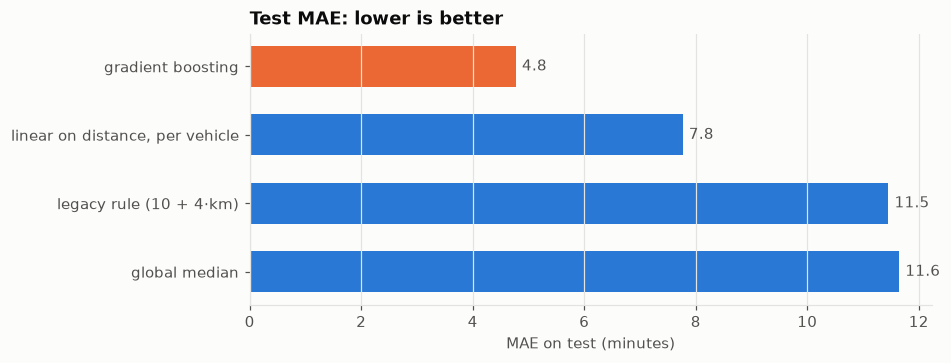

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
order = results["MAE (min)"].sort_values(ascending=False)
bars = ax.barh(
    order.index,
    order.to_numpy(),
    color=[SERIES[1] if n == "gradient boosting" else SERIES[0] for n in order.index],
    height=0.6,
)
ax.bar_label(bars, labels=[f"{v:.1f}" for v in order.to_numpy()], padding=4, color=INK_SECONDARY)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("MAE on test (minutes)")
ax.set_title("Test MAE: lower is better")
plt.show()

The legacy rule is barely better than a constant: it ignores vehicle, traffic, rain and merchant prep time.
The per-vehicle linear model already helps a lot; gradient boosting cuts the error again, mostly by capturing
interactions (vehicle × distance, peak hour × city congestion, rain × two-wheelers) and the effect of pulser load.

### 4.1 · Where is the model still wrong?

In [7]:
seg = test.assign(
    abs_err=np.abs(preds["gradient boosting"] - y_test),
    legacy_err=np.abs(preds["legacy rule (10 + 4·km)"] - y_test),
    peak=test["hour"].isin([13, 14, 18, 19, 20]),
)
pd.concat(
    {
        dim: seg.groupby(dim, observed=True)[["abs_err", "legacy_err"]].mean()
        for dim in ("vehicle", "city", "raining", "peak")
    }
).rename(columns={"abs_err": "GBM MAE", "legacy_err": "legacy MAE"}).style.format("{:.2f}")

Errors grow where the target is noisier (cars in traffic, rain, peak hours), but the model beats the rule in
every segment — it does not buy its average by failing on a subgroup.

## 5 · Calibration and an uncertainty band

A point estimate is not what a merchant needs; they need a promise we can keep. Two checks:

* **Calibration of the point estimate:** within each decile of predicted minutes, does the actual median match?
* **Interval coverage:** fit quantile models for p10 and p90 and check that ~80 % of test orders land inside.

p10-p90 interval coverage on test: 77.7% (target 80%)
median interval width: 13.0 min
share of orders later than the p90 quote: 11.0% (target 10%)


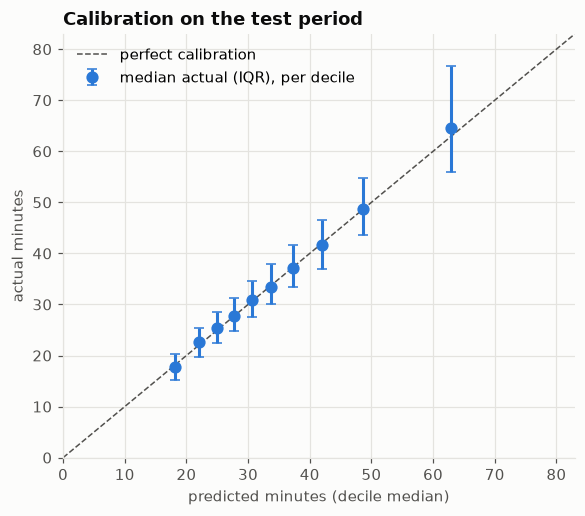

In [8]:
q_models = {
    q: gbm(loss="quantile", quantile=q).fit(X_train, y_train, X_val=X_valid, y_val=y_valid)
    for q in (0.1, 0.5, 0.9)
}
p10, p90 = q_models[0.1].predict(X_test), q_models[0.9].predict(X_test)
coverage = ((y_test >= p10) & (y_test <= p90)).mean()
print(f"p10-p90 interval coverage on test: {coverage:.1%} (target 80%)")
print(f"median interval width: {np.median(p90 - p10):.1f} min")
print(f"share of orders later than the p90 quote: {(y_test > p90).mean():.1%} (target 10%)")

cal = pd.DataFrame({"pred": preds["gradient boosting"], "actual": y_test})
cal["decile"] = pd.qcut(cal["pred"], 10, labels=False)
by_dec = cal.groupby("decile").agg(
    pred=("pred", "median"),
    actual=("actual", "median"),
    q25=("actual", lambda x: x.quantile(0.25)),
    q75=("actual", lambda x: x.quantile(0.75)),
)
fig, ax = plt.subplots(figsize=(6, 5))
lim = [0, by_dec[["pred", "q75"]].to_numpy().max() * 1.08]
ax.plot(lim, lim, color=INK_SECONDARY, linestyle="--", linewidth=1, label="perfect calibration")
ax.errorbar(
    by_dec["pred"],
    by_dec["actual"],
    yerr=[by_dec["actual"] - by_dec["q25"], by_dec["q75"] - by_dec["actual"]],
    fmt="o",
    color=SERIES[0],
    markersize=7,
    capsize=3,
    label="median actual (IQR), per decile",
)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("predicted minutes (decile median)")
ax.set_ylabel("actual minutes")
ax.set_title("Calibration on the test period")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper left")
plt.show()

The point estimate sits on the diagonal across the range. The p10–p90 band covers slightly less than the nominal
80 % (the test period comes after the training period, so a bit of under-coverage is expected); a conformal adjustment
on the validation week would widen it to the target.
That band is what product should use: quote the **p90** as "arrives by" (on time ~9 times in 10), and show the median as
the expected time. Quantile crossing (p10 > p90) can happen with independent quantile models; it is rare here and would
be fixed by sorting the three predictions at serving time.

Stuck orders are excluded from training, so no model will predict them; on the full test period (stuck included)
they show up as rare, very large misses:

In [9]:
all_pred = model.predict(test_all[FEATURES])
miss = all_pred - test_all["delivery_minutes"].to_numpy()
print(
    f"test orders incl. stuck: {len(test_all):,}; later than prediction by > 60 min: {(miss < -60).mean():.2%}"
)
print(f"of those, flagged stuck: {test_all.loc[miss < -60, 'stuck'].mean():.0%}")

test orders incl. stuck: 10,742; later than prediction by > 60 min: 0.34%
of those, flagged stuck: 89%


## 6 · What drives the prediction?

Permutation importance on the **test** set: how much MAE gets worse when one feature is shuffled. Unlike split-count
importance it measures what the model actually relies on for out-of-sample accuracy.

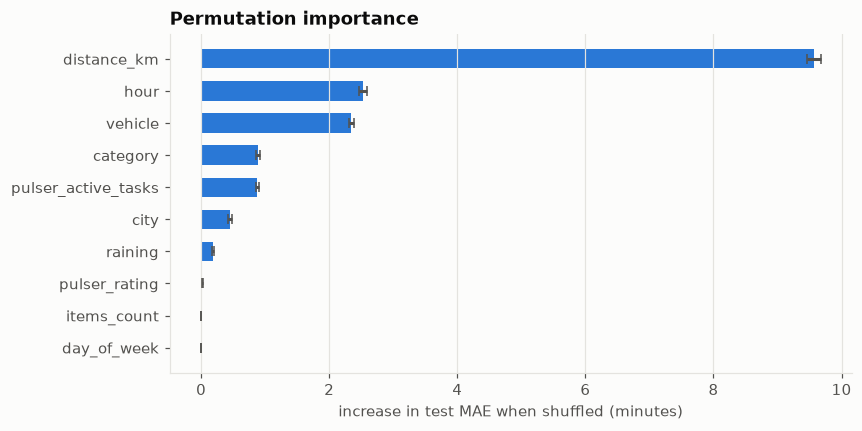

In [10]:
sample = test.sample(5_000, random_state=0)
imp = permutation_importance(
    model,
    sample[FEATURES],
    sample["delivery_minutes"],
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=0,
)
importance = pd.DataFrame(
    {"mean": imp.importances_mean, "std": imp.importances_std}, index=FEATURES
).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    importance.index,
    importance["mean"],
    xerr=importance["std"],
    color=SERIES[0],
    height=0.6,
    error_kw={"ecolor": INK_SECONDARY, "capsize": 3},
)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("increase in test MAE when shuffled (minutes)")
ax.set_title("Permutation importance")
plt.show()

Distance dominates, followed by hour (lunch/dinner traffic and pulser load) and vehicle; then merchant category (prep
time differs between a pharmacy and a restaurant), pulser load and city congestion. Rain matters less on average because
it only hits some days and mostly two-wheelers. Weekday and item count contribute nothing — consistent with the
simulator, which has no weekly pattern and does not use item count — so they are candidates to drop. Pulser rating is
also near zero: its true effect in the generator is small (≈ 3 % per rating point) and is swamped by noise.

## 7 · Serving: latency and footprint

The quote is computed inside the order-creation request, so latency matters as much as accuracy. Measured on this
laptop (single process, CPU):

In [11]:
one = X_test.iloc[[0]]
model.predict(one)  # warm-up


def timeit(fn, n):
    t = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        t.append(time.perf_counter() - t0)
    return np.array(t) * 1000


single = timeit(lambda: model.predict(one), 300)
batch = timeit(lambda: model.predict(X_test.iloc[:1_000]), 30)
size_kb = len(pickle.dumps(model)) / 1024
pd.DataFrame(
    {
        "value": [
            f"{np.percentile(single, 50):.2f} ms",
            f"{np.percentile(single, 99):.2f} ms",
            f"{np.percentile(batch, 50):.2f} ms",
            f"{np.percentile(batch, 50) * 1_000 / 1_000:.1f} µs",
            f"{size_kb:,.0f} KB",
            f"{model.n_iter_}",
        ],
    },
    index=[
        "single-row predict, p50",
        "single-row predict, p99",
        "batch of 1,000, p50",
        "per row in batch",
        "pickled model size",
        "trees",
    ],
)

,value
"single-row predict, p50",17.05 ms
"single-row predict, p99",23.41 ms
"batch of 1,000, p50",27.74 ms
per row in batch,27.7 µs
pickled model size,"1,653 KB"
trees,425


A single prediction costs about as much as a batch of 1,000: almost all of it is per-call overhead (pandas input
validation, categorical encoding, thread pool start-up), not tree traversal, so per row a batch is two to three orders
of magnitude cheaper. Absolute numbers depend on the machine and its load; the ratio is the point.
Practical options, in order of effort:

1. **Batch where possible** (re-quoting open orders every minute is a batch job).
2. Pass a pre-encoded **NumPy array** instead of a DataFrame and pin `OMP_NUM_THREADS=1` in the serving process.
3. Compile the trees (e.g. ONNX Runtime or Treelite) for a sub-millisecond, dependency-light scorer if the single-row
   path is on a hot request.

The model is small enough to load in every API replica; no separate model server is needed at this scale.

## 8 · Conclusions

| | legacy rule | gradient boosting |
|---|---|---|
| test MAE | 11.5 min | **4.8 min** (−58 %) |
| bias | −10.5 min (quotes too optimistic) | −0.6 min |
| orders > 10 min later than quoted | 45 % | **7 %** |
| within ±5 min | 31 % | **64 %** |

* The legacy `10 + 4·km` quote is no better than a constant and is systematically optimistic, which is exactly what
  produces "late" orders and refunds. A per-vehicle linear model is a cheap first step (MAE 7.8); gradient boosting
  halves the remaining error.
* The model is calibrated on a later, unseen period, and quantile models give a usable "arrives by" (p90) promise.
* Serving is cheap if batched; the single-row path needs a compiled scorer or NumPy input if it sits on a hot request.

**Limitations.** The data is simulated: the generator has a known functional form, so the model's job is easier than in
reality and the absolute numbers mean nothing outside this notebook. A production version would need road-network
distance instead of straight-line, live supply/demand features, drift monitoring (weekly MAE and coverage by city), and
an online A/B test of the new quote against merchant conversion and refund rate — the methods of notebook 02.
